In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data Analysis and Visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_ImadolLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,pm25,49.250000,µg/m³,2025-11-06 12:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,12:45:00
1,6121047,Imadol(SC-27)- GD Labs,pm25,28.694500,µg/m³,2025-11-06 13:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,13:45:00
2,6121047,Imadol(SC-27)- GD Labs,pm25,21.965042,µg/m³,2025-11-06 14:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,14:45:00
3,6121047,Imadol(SC-27)- GD Labs,pm25,27.629958,µg/m³,2025-11-06 15:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,15:45:00
4,6121047,Imadol(SC-27)- GD Labs,pm25,34.937583,µg/m³,2025-11-06 16:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2025-11-06,16:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6121047,Imadol(SC-27)- GD Labs,pm25,94.600000,µg/m³,2026-02-26 17:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,17:45:00
996,6121047,Imadol(SC-27)- GD Labs,pm25,100.000000,µg/m³,2026-02-26 18:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,18:45:00
997,6121047,Imadol(SC-27)- GD Labs,pm25,109.900000,µg/m³,2026-02-26 19:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,19:45:00
998,6121047,Imadol(SC-27)- GD Labs,pm25,101.000000,µg/m³,2026-02-26 20:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-02-26,20:45:00


In [3]:
df365['date'].unique()

<ArrowStringArray>
['2025-11-06', '2025-11-07', '2025-11-08', '2025-11-09', '2025-11-10',
 '2025-11-11', '2025-11-12', '2025-11-13', '2025-11-14', '2025-11-15',
 '2025-11-16', '2025-11-17', '2025-11-18', '2025-11-19', '2025-11-20',
 '2025-11-21', '2025-11-22', '2025-11-23', '2025-11-24', '2025-11-25',
 '2025-11-26', '2026-02-03', '2026-02-04', '2026-02-05', '2026-02-06',
 '2026-02-07', '2026-02-08', '2026-02-09', '2026-02-10', '2026-02-11',
 '2026-02-12', '2026-02-13', '2026-02-14', '2026-02-15', '2026-02-16',
 '2026-02-17', '2026-02-18', '2026-02-19', '2026-02-20', '2026-02-21',
 '2026-02-22', '2026-02-23', '2026-02-24', '2026-02-25', '2026-02-26']
Length: 45, dtype: str

### Aggrigating hourly data to daily means, and filling only short gaps(1 to 2 days) by interpolation

In [4]:
# 1. Load hourly data observations
hourly = df365

# Ensure date and PM2.5 values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [5]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [6]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [7]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [ ]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [8]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [9]:
daily

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2025-11-06,2025-11-06,12.0,observed
1,2025-11-07,2025-11-07,24.0,observed
2,2025-11-08,2025-11-08,24.0,observed
3,2025-11-09,2025-11-09,14.0,observed
4,2025-11-10,2025-11-10,18.0,observed
...,...,...,...,...
108,2026-02-22,2026-02-22,24.0,observed
109,2026-02-23,2026-02-23,24.0,observed
110,2026-02-24,2026-02-24,24.0,observed
111,2026-02-25,2026-02-25,24.0,observed


In [10]:
daily.columns

Index(['date', 'pm25_daily_mean_ug_m3', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

### Plotting daily aggrigate value

/tmp/ipykernel_7738/1055801732.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


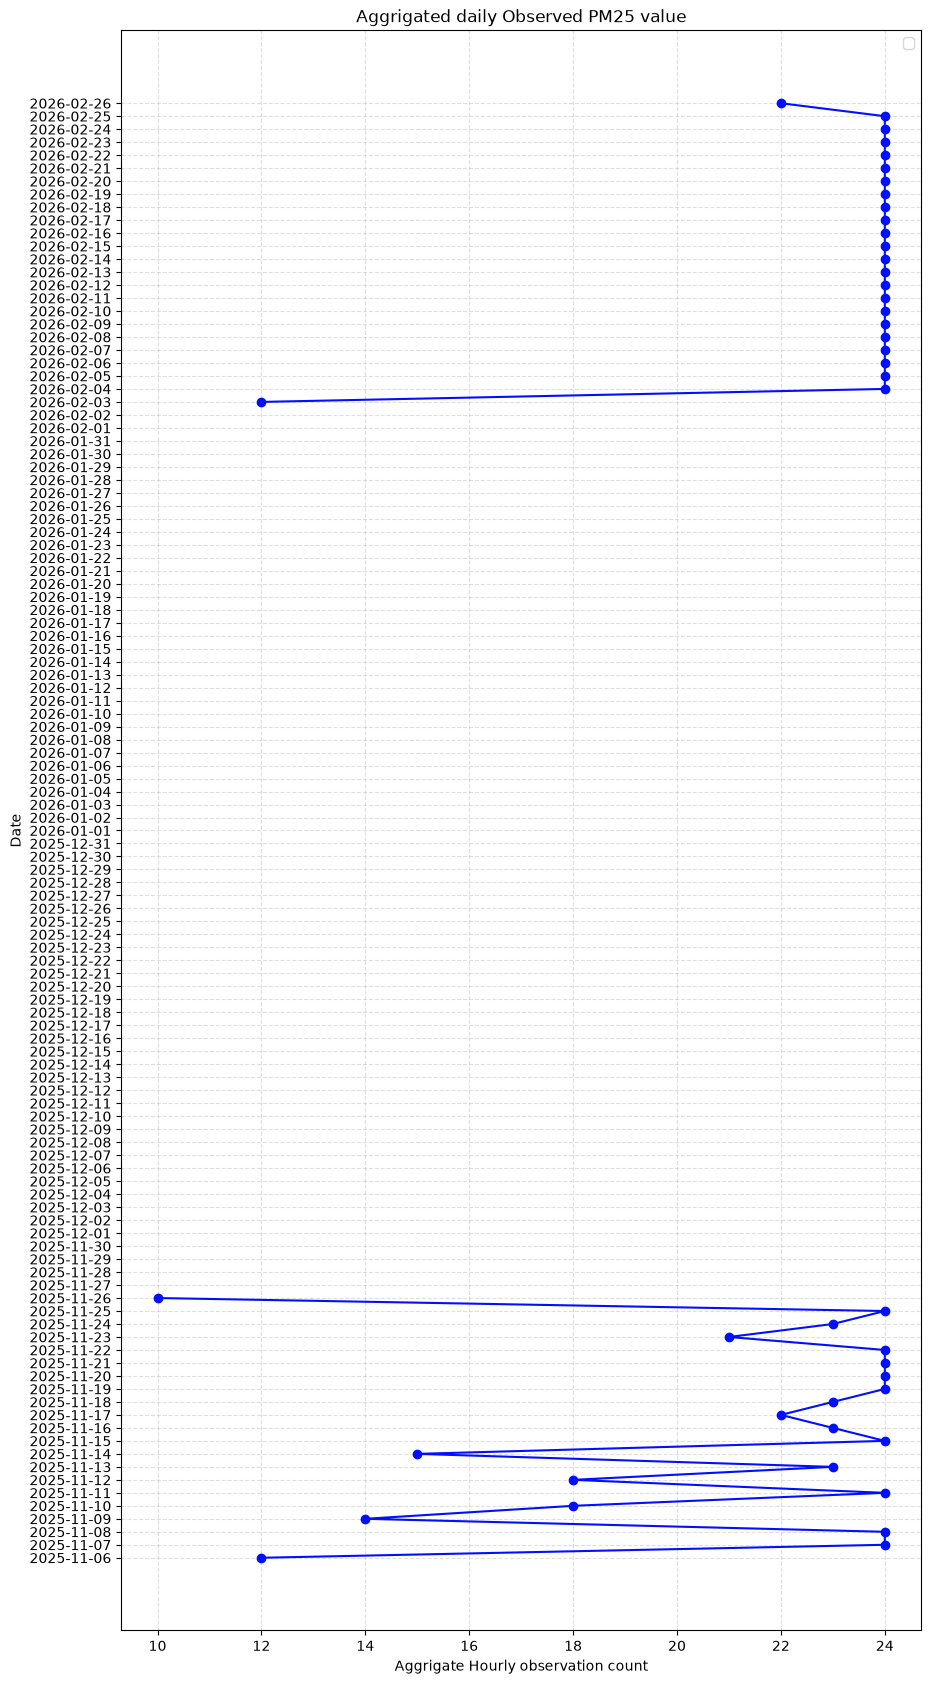

In [14]:
fig = plt.figure(figsize=(10, 20))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and visualization of last 30 days

In [15]:
df30 = pd.read_csv('cleaned_ImadolLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,pm25,25.7,µg/m³,2026-09-05 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,pm25,24.1,µg/m³,2026-09-05 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,pm25,26.0,µg/m³,2026-09-05 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,pm25,27.0,µg/m³,2026-09-05 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,pm25,19.8,µg/m³,2026-09-05 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-09-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
879,6121047,Imadol(SC-27)- GD Labs,pm25,32.6,µg/m³,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
880,6121047,Imadol(SC-27)- GD Labs,pm25,32.9,µg/m³,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
881,6121047,Imadol(SC-27)- GD Labs,pm25,33.1,µg/m³,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
882,6121047,Imadol(SC-27)- GD Labs,pm25,30.6,µg/m³,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [16]:
df30['date'].unique

<bound method Series.unique of 0      2026-09-05
1      2026-09-05
2      2026-09-05
3      2026-09-05
4      2026-09-05
          ...    
879    2026-10-12
880    2026-10-12
881    2026-10-12
882    2026-10-12
883    2026-10-12
Name: date, Length: 884, dtype: str>

### Aggrigate hourly data to daily means, and filling only short gaps (1 to 2 days) by interpolation

In [17]:
# 1. Load hourly data observations
hourly = df30

# Ensure date and PM2.5 values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [18]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [19]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [20]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [21]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [22]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [23]:
daily

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2026-09-05,2026-09-05,18,observed
1,2026-09-06,2026-09-06,24,observed
2,2026-09-07,2026-09-07,24,observed
3,2026-09-08,2026-09-08,24,observed
4,2026-09-09,2026-09-09,24,observed
5,2026-09-10,2026-09-10,24,observed
6,2026-09-11,2026-09-11,24,observed
7,2026-09-12,2026-09-12,24,observed
8,2026-09-13,2026-09-13,24,observed
9,2026-09-14,2026-09-14,24,observed


In [24]:
daily.columns

Index(['date', 'pm25_daily_mean_ug_m3', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

/tmp/ipykernel_7738/18109499.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


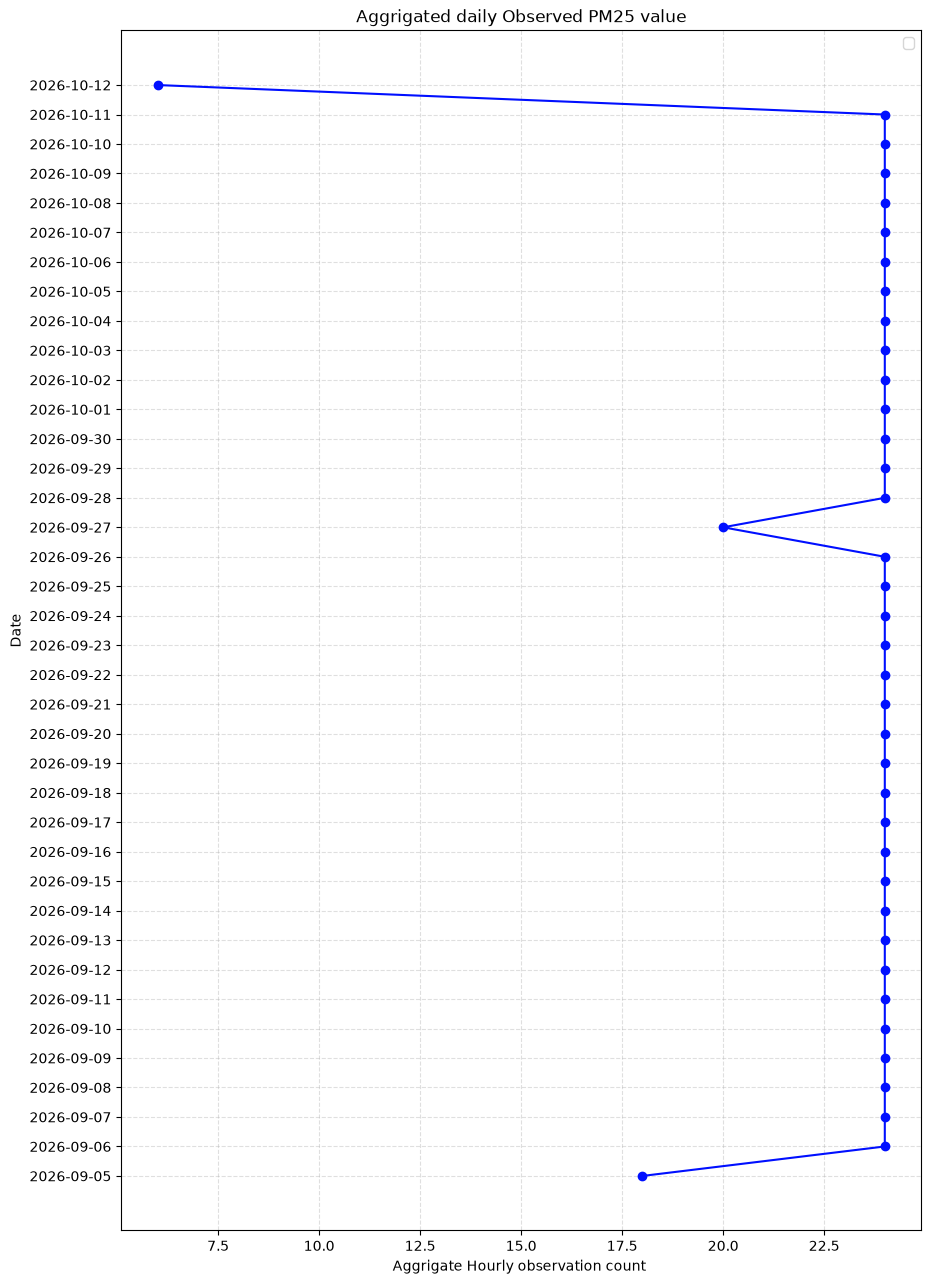

In [25]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [26]:
df7 = pd.read_csv('cleaned_ImadolLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,pm25,47.7,µg/m³,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,pm25,50.1,µg/m³,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,pm25,48.5,µg/m³,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,pm25,48.8,µg/m³,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,pm25,46.6,µg/m³,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6121047,Imadol(SC-27)- GD Labs,pm25,32.6,µg/m³,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,6121047,Imadol(SC-27)- GD Labs,pm25,32.9,µg/m³,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,6121047,Imadol(SC-27)- GD Labs,pm25,33.1,µg/m³,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,6121047,Imadol(SC-27)- GD Labs,pm25,30.6,µg/m³,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [27]:
df7['date'].unique()

<ArrowStringArray>
['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09',
 '2026-10-10', '2026-10-11', '2026-10-12']
Length: 8, dtype: str

### Aggrigating hourly data to daily means, and filling only short gaps (1 to 2 days) by interpolation

In [29]:
# 1. Load hourly data observations
hourly = df7

# Ensure date and PM2.5 values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [30]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [31]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [32]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [33]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [34]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [35]:
daily

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2026-10-05,2026-10-05,18,observed
1,2026-10-06,2026-10-06,24,observed
2,2026-10-07,2026-10-07,24,observed
3,2026-10-08,2026-10-08,24,observed
4,2026-10-09,2026-10-09,24,observed
5,2026-10-10,2026-10-10,24,observed
6,2026-10-11,2026-10-11,24,observed
7,2026-10-12,2026-10-12,6,observed


In [36]:
daily.columns

Index(['date', 'pm25_daily_mean_ug_m3', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

/tmp/ipykernel_7738/1788375289.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


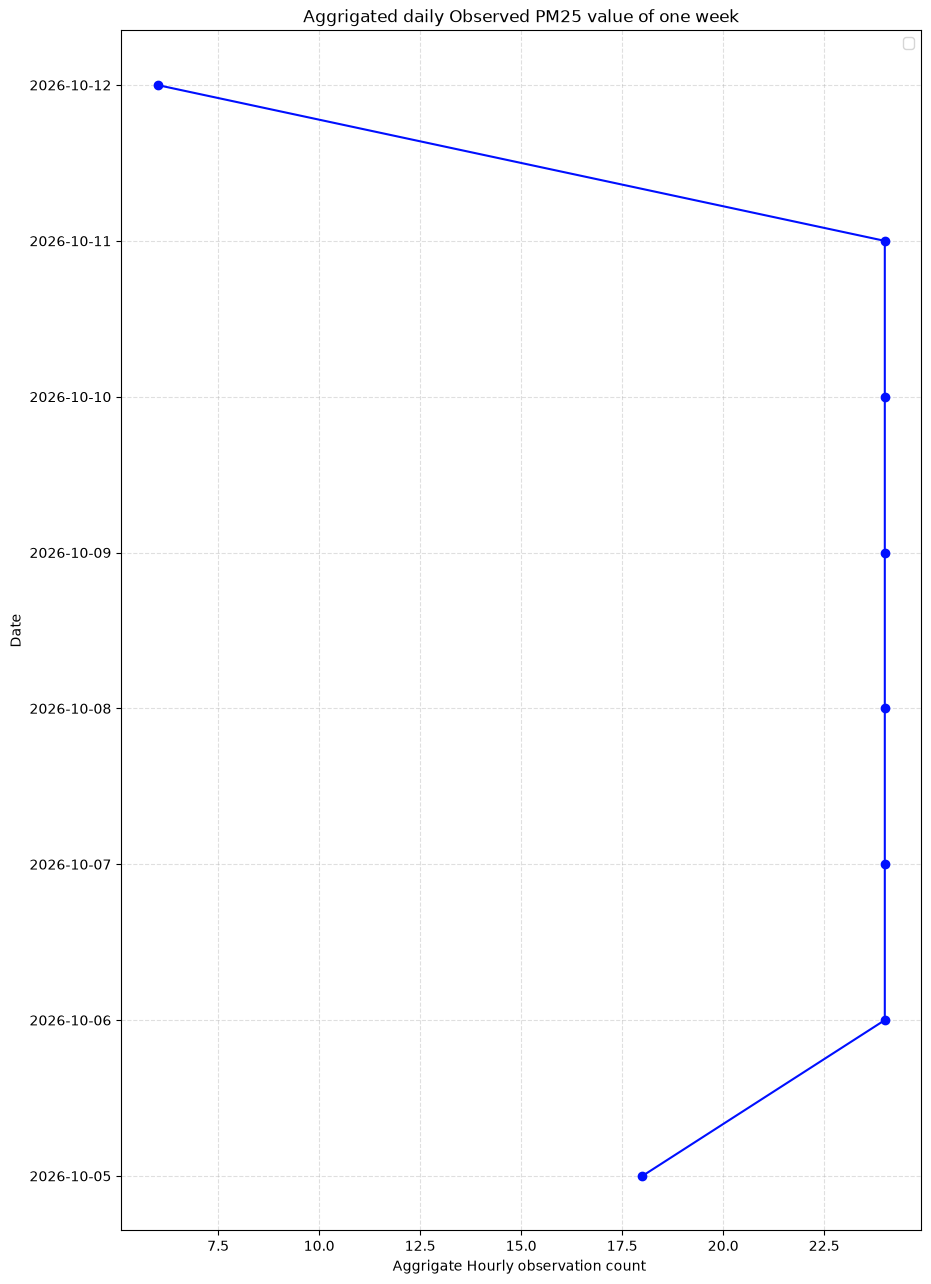

In [37]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [38]:
df24 = pd.read_csv('cleaned_ImadolLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121047,Imadol(SC-27)- GD Labs,pm25,33.5,µg/m³,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6121047,Imadol(SC-27)- GD Labs,pm25,36.5,µg/m³,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6121047,Imadol(SC-27)- GD Labs,pm25,41.3,µg/m³,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6121047,Imadol(SC-27)- GD Labs,pm25,43.3,µg/m³,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6121047,Imadol(SC-27)- GD Labs,pm25,32.4,µg/m³,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6121047,Imadol(SC-27)- GD Labs,pm25,30.3,µg/m³,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6121047,Imadol(SC-27)- GD Labs,pm25,27.7,µg/m³,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6121047,Imadol(SC-27)- GD Labs,pm25,26.1,µg/m³,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6121047,Imadol(SC-27)- GD Labs,pm25,23.9,µg/m³,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6121047,Imadol(SC-27)- GD Labs,pm25,24.1,µg/m³,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.661062,85.347716,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


In [39]:
df24['time'].unique

<bound method Series.unique of 0     06:45:00
1     07:45:00
2     08:45:00
3     09:45:00
4     10:45:00
5     11:45:00
6     12:45:00
7     13:45:00
8     14:45:00
9     15:45:00
10    16:45:00
11    17:45:00
12    18:45:00
13    19:45:00
14    20:45:00
15    21:45:00
16    22:45:00
17    23:45:00
18    00:45:00
19    01:45:00
20    02:45:00
21    03:45:00
22    04:45:00
23    05:45:00
Name: time, dtype: str>

/tmp/ipykernel_7738/1789865348.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


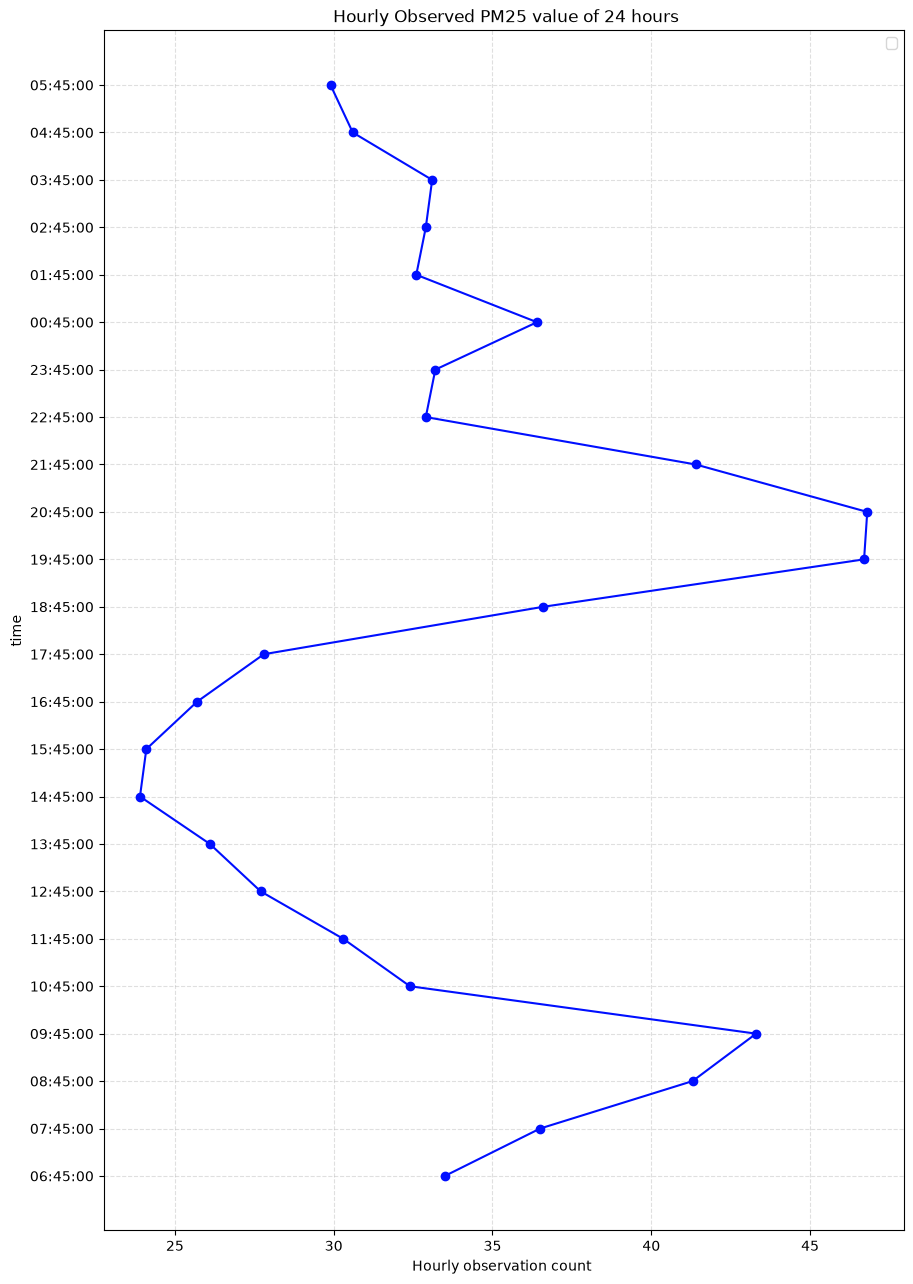

In [40]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(df24['value'], df24['time'], color ='#000fff', marker='o')
plt.xlabel('Hourly observation count ')
plt.ylabel('time')
plt.title(" Hourly Observed PM25 value of 24 hours")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()